# HYROX 대회 기록 분석 : 군집

**구간 시간 배분이 비슷한 기록끼리 묶고, 군집별 특성을 비교하는 단계**

## 개요
- 목적: 시간 배분 특징 기준의 기록 그룹화 및 군집별 특성 비교
- 데이터: 02에서 저장한 분석용 데이터 `clean` 59,886건. 분석 범위는 open·pro 부문
- 환경: Python 3.12.15 / pandas 3.0.6 / scikit-learn 1.9.1 (conda `hyrox-analysis`)
- 도구: VS Code, Claude

## 구성
1. 데이터 불러오기·특징 후보 확인
   - 작업: `hyrox_clean.csv`를 읽고 시간 배분 특징 후보를 계산해 분포·상관 확인
   - 도출: 특징 후보 `features`
2. 특징 선택·표준화
   - 작업: 군집 입력 특징을 선택하고 표준화
   - 도출: 군집 입력 `X`(입력 A), 비교용 입력 `X_alt`(입력 B)
3. 군집 수 정하기
   - 작업: k=2~5에서 K-Means의 관성·실루엣 점수 비교
   - 도출: 군집 수 k
4. 군집 결과 해석
   - 작업: 선택한 k로 군집을 학습하고 군집별 특징·총 기록·구성 비교
   - 도출: 군집별 프로파일 표


In [11]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score

plt.rc("font", family="Malgun Gothic")  # 한글 표시 오류 방지를 위한 폰트 지정(Windows 기준)
plt.rc("axes", unicode_minus=False)  # 음수 부호(-) 표시 오류 방지

## 1. 데이터 불러오기·특징 후보 확인

**핵심:** 02에서 저장한 `clean`을 불러와 시간 배분 특징 후보 4개를 계산하고 분포와 상관을 확인

### 작업 내용
- CSV 읽기: `hyrox_clean.csv` 사용 (`clean` 59,886건)
- 특징 후보 4개 계산
  - 런 비중: `run_time_sec` ÷ `total_sec`
  - 스테이션 비중: `work_time_sec` ÷ `total_sec`
  - 록스존 비중: `roxzone_time_sec` ÷ `total_sec`
  - 후반 런 하락: 런 5~8구간 평균 ÷ 런 1~4구간 평균
- 후보별 요약 통계(`describe`)와 후보 간 상관 확인
- 후보 4개의 분포를 히스토그램(2×2)으로 확인

### 확인 포인트
- 후보 4개의 분포 (중앙값, 5%·95%)
- 후보 간 상관 (비중 3개의 상관 포함)

In [12]:
# notebooks/ 폴더 기준 상대 경로로 data/ 폴더 접근
clean = pd.read_csv("../data/hyrox_clean.csv")  # 02에서 저장한 분석용 데이터
print("clean.shape:", clean.shape)

run_early = clean[[f"run_{i}_sec" for i in range(1, 5)]].mean(axis=1)  # 런 1~4구간 평균
run_late = clean[[f"run_{i}_sec" for i in range(5, 9)]].mean(axis=1)  # 런 5~8구간 평균

features = pd.DataFrame({
    "런 비중": clean["run_time_sec"] / clean["total_sec"],
    "스테이션 비중": clean["work_time_sec"] / clean["total_sec"],
    "록스존 비중": clean["roxzone_time_sec"] / clean["total_sec"],
    "후반 런 하락": run_late / run_early,  # 1보다 클수록 후반 런이 전반보다 느림
})
print(features.describe(percentiles=[0.05, 0.5, 0.95]).round(3).to_string())
print(features.corr().round(2).to_string())
share_sum = features[["런 비중", "스테이션 비중", "록스존 비중"]].sum(axis=1)  # 세 비중의 합
print("세 비중 합 최솟값·최댓값:", share_sum.min(), share_sum.max())

clean.shape: (59886, 67)
            런 비중    스테이션 비중     록스존 비중    후반 런 하락
count  59886.000  59886.000  59886.000  59886.000
mean       0.502      0.423      0.076      1.125
std        0.036      0.036      0.020      0.102
min        0.222      0.217      0.025      0.580
5%         0.441      0.367      0.049      0.995
50%        0.503      0.421      0.074      1.114
95%        0.558      0.484      0.109      1.291
max        0.717      0.714      0.436      2.979
         런 비중  스테이션 비중  록스존 비중  후반 런 하락
런 비중     1.00    -0.86   -0.27    -0.04
스테이션 비중 -0.86     1.00   -0.27    -0.03
록스존 비중  -0.27    -0.27    1.00     0.13
후반 런 하락 -0.04    -0.03    0.13     1.00
세 비중 합 최솟값·최댓값: 0.9999999999999999 1.0000000000000002


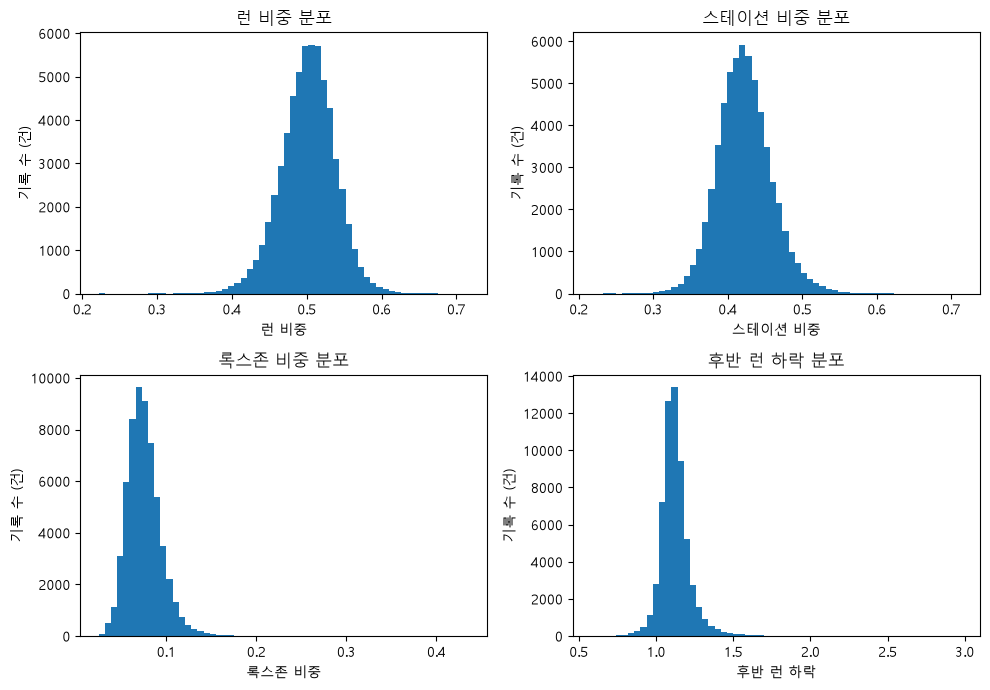

In [13]:
fig, axes = plt.subplots(2, 2, figsize=(10, 7))
for ax, col in zip(axes.ravel(), features.columns):
    ax.hist(features[col], bins=60)  # 전체 분포 확인용
    ax.set_xlabel(col)
    ax.set_ylabel("기록 수 (건)")
    ax.set_title(f"{col} 분포")
plt.tight_layout()
plt.show()

### 결과
- 후보 4개 모두 봉우리가 하나인 분포
- 세 비중(런·스테이션·록스존)의 합은 전 기록에서 1.0
- 런 비중-스테이션 비중 상관 -0.86, 후반 런 하락과는 모두 |r| ≤ 0.13
- 록스존 비중·후반 런 하락은 오른쪽 꼬리가 길고, 최댓값은 0.436·2.979

**후보별 요약 통계**

| 후보 | 중앙값 | 5% | 95% |
|---|---|---|---|
| 런 비중 | 0.503 | 0.441 | 0.558 |
| 스테이션 비중 | 0.421 | 0.367 | 0.484 |
| 록스존 비중 | 0.074 | 0.049 | 0.109 |
| 후반 런 하락 | 1.114 | 0.995 | 1.291 |

**후보 간 상관**

| | 런 비중 | 스테이션 비중 | 록스존 비중 | 후반 런 하락 |
|---|---|---|---|---|
| 런 비중 | 1.00 | -0.86 | -0.27 | -0.04 |
| 스테이션 비중 | -0.86 | 1.00 | -0.27 | -0.03 |
| 록스존 비중 | -0.27 | -0.27 | 1.00 | 0.13 |
| 후반 런 하락 | -0.04 | -0.03 | 0.13 | 1.00 |

### 추정·한계
- 봉우리가 하나라 뚜렷하게 갈라지는 유형은 없을 가능성이 있음 (군집 결과로 재확인)
- 록스존 비중·후반 런 하락의 긴 오른쪽 꼬리가 극단 기록인지 실제 기록인지 구분 불가

### 한 줄 정리
- 특징 후보 4개는 모두 한 봉우리 분포이고, 런 비중과 스테이션 비중은 상관 -0.86으로 강하게 묶여 있음

## 2. 특징 선택·표준화

**핵심:** 군집 입력 A(런 비중, 후반 런 하락)를 선택하고 입력 A·B를 표준화

### 작업 내용
- 입력 A: 런 비중, 후반 런 하락
- 입력 B: 런 비중, 스테이션 비중 (비교용)
- 록스존 비중: 입력에서 제외, 4절에서 군집별 비교용으로 사용
- 표준화: 입력별로 평균 0, 표준편차 1로 변환 (`StandardScaler`)
- 표준화 전후 요약 통계(`describe`) 확인

### 확인 포인트
- 입력 특징의 열 구성
- 표준화 후 평균·표준편차

In [14]:
X_cols = ["런 비중", "후반 런 하락"]  # 입력 A
alt_cols = ["런 비중", "스테이션 비중"]  # 입력 B (비교용)

X = StandardScaler().fit_transform(features[X_cols])  # 표준화
X_alt = StandardScaler().fit_transform(features[alt_cols])

print("입력 A:", X_cols)
print(features[X_cols].describe().round(3).to_string())
print(pd.DataFrame(X, columns=X_cols).describe().round(3).to_string())
print("입력 B:", alt_cols)
print(features[alt_cols].describe().round(3).to_string())
print(pd.DataFrame(X_alt, columns=alt_cols).describe().round(3).to_string())

입력 A: ['런 비중', '후반 런 하락']
            런 비중    후반 런 하락
count  59886.000  59886.000
mean       0.502      1.125
std        0.036      0.102
min        0.222      0.580
25%        0.479      1.070
50%        0.503      1.114
75%        0.525      1.165
max        0.717      2.979
            런 비중    후반 런 하락
count  59886.000  59886.000
mean       0.000      0.000
std        1.000      1.000
min       -7.679     -5.341
25%       -0.613     -0.540
50%        0.038     -0.105
75%        0.653      0.398
max        5.906     18.172
입력 B: ['런 비중', '스테이션 비중']
            런 비중    스테이션 비중
count  59886.000  59886.000
mean       0.502      0.423
std        0.036      0.036
min        0.222      0.217
25%        0.479      0.399
50%        0.503      0.421
75%        0.525      0.445
max        0.717      0.714
            런 비중    스테이션 비중
count  59886.000  59886.000
mean       0.000      0.000
std        1.000      1.000
min       -7.679     -5.661
25%       -0.613     -0.656
50%        0.038     -0.

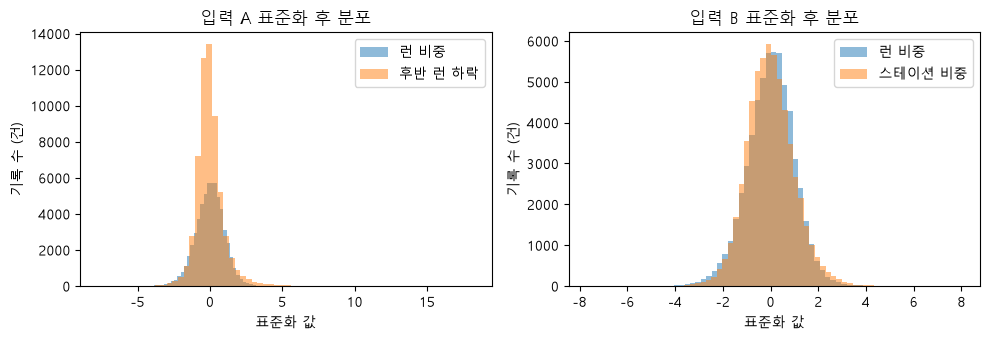

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
for ax, col, vals in [(axes[0], "입력 A", X), (axes[1], "입력 B", X_alt)]:
    for j, name in enumerate(X_cols if col == "입력 A" else alt_cols):
        ax.hist(vals[:, j], bins=60, alpha=0.5, label=name)  # 표준화 후 분포
    ax.set_xlabel("표준화 값")
    ax.set_ylabel("기록 수 (건)")
    ax.set_title(f"{col} 표준화 후 분포")
    ax.legend()
plt.tight_layout()
plt.show()

### 결과
- 입력 열 구성: 입력 A `런 비중`·`후반 런 하락`, 입력 B `런 비중`·`스테이션 비중`
- 표준화 후 평균 0.000, 표준편차 1.000 (입력 A)
- 표준화 후 최댓값: 후반 런 하락 18.172, 런 비중 5.906 (입력 A)
- 표준화 후 최댓값: 스테이션 비중 7.995, 런 비중 5.906 (입력 B)

**입력 A 표준화 후 최솟값·최댓값**

| 특징 | 최솟값 | 최댓값 |
|---|---|---|
| 런 비중 | -7.679 | 5.906 |
| 후반 런 하락 | -5.341 | 18.172 |

### 추정·한계
- 후반 런 하락의 극단 기록이 군집 중심에 영향을 줄 수 있음 (4절에서 확인)
- 극단 기록은 02 기준을 유지하고 추가로 제외하지 않음

### 한 줄 정리
- 런 비중과 후반 런 하락을 표준화해 군집 입력(입력 A)으로 정했고, 후반 런 하락의 표준화 후 최댓값은 18.172임

## 3. 군집 수 정하기

**핵심:** k=2~5에서 관성과 실루엣 점수를 비교해 군집 수(k)를 정함

### 작업 내용
- 군집 수 범위: 해석 가능한 수준을 고려해 k=2~5로 설정
- 표본 크기 확인: k=3 하나로 5,000·10,000·20,000건의 실루엣 비교 (실루엣 계산용 표본 크기 점검)
- 군집 시작 횟수 확인: `n_init` 1·10·30의 관성·군집 크기 비교 (k=3, `random_state=42`)
- 입력 A(`X`)와 입력 B(`X_alt`)에 대해 K-Means(`n_init=10`, `random_state=42`) 학습
- k별 관성과 실루엣 점수 계산 (실루엣은 10,000건 표본)
- 관성·실루엣 점수를 그래프로 확인

### 확인 포인트
- 표본 크기별 실루엣 점수 차이
- `n_init`별 관성·군집 크기 차이
- k별 관성의 감소 폭과 꺾이는 지점 유무
- 실루엣 점수가 가장 큰 k
- 입력 A와 입력 B의 k별 점수 경향 차이

In [16]:
km3 = KMeans(n_clusters=3, n_init=10, random_state=42).fit(X)  # 표본 크기 확인용 임시 k (k 선택과 무관)
rows = []
for size in [5000, 10000, 20000]:
    s = np.random.RandomState(42).choice(len(X), size, replace=False)  # 표본 크기별 무작위 추출
    rows.append({"표본 크기": size, "실루엣": round(silhouette_score(X[s], km3.labels_[s]), 3)})
print(pd.DataFrame(rows).to_string(index=False))

 표본 크기   실루엣
  5000 0.351
 10000 0.353
 20000 0.357


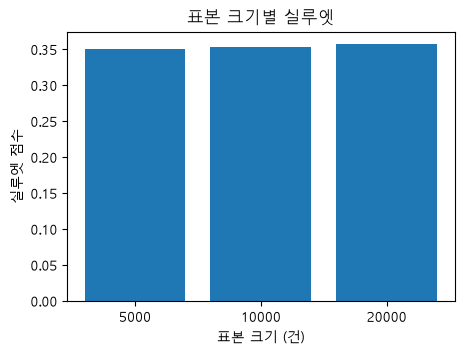

In [17]:
plt.figure(figsize=(5, 3.5))
plt.bar([str(r["표본 크기"]) for r in rows], [r["실루엣"] for r in rows])
plt.xlabel("표본 크기 (건)")
plt.ylabel("실루엣 점수")
plt.title("표본 크기별 실루엣")
plt.show()

In [18]:
rows = []
for n in [1, 10, 30]:
    m = KMeans(n_clusters=3, n_init=n, random_state=42).fit(X)  # 입력 A, k=3
    sizes = sorted(np.bincount(m.labels_), reverse=True)  # 군집 번호 순서와 무관하게 크기만 비교
    rows.append({"n_init": n, "관성": round(m.inertia_), "군집 기록 수 (건)": sizes})
print(pd.DataFrame(rows).to_string(index=False))

 n_init    관성          군집 기록 수 (건)
      1 59699 [29539, 23014, 7333]
     10 59697 [29369, 23448, 7069]
     30 59697 [29369, 23448, 7069]


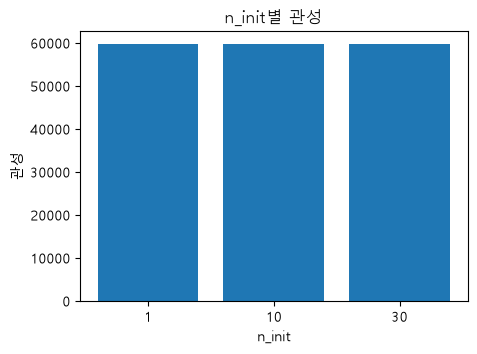

In [19]:
plt.figure(figsize=(5, 3.5))
plt.bar([str(r["n_init"]) for r in rows], [r["관성"] for r in rows])
plt.xlabel("n_init")
plt.ylabel("관성")
plt.title("n_init별 관성")
plt.show()

In [20]:
rng = np.random.RandomState(42)
sample = rng.choice(len(X), 10000, replace=False)  # 실루엣 계산용 표본

def k_scores(data):
    """k=2~5에서 관성과 실루엣 점수 계산"""
    rows = []
    for k in range(2, 6):
        km = KMeans(n_clusters=k, n_init=10, random_state=42).fit(data)  # data = 전체 59,886건
        sil = silhouette_score(data[sample], km.labels_[sample])  # 점수만 표본 10,000건으로
        rows.append({"k": k, "관성": round(km.inertia_), "실루엣": round(sil, 3)})
    return pd.DataFrame(rows)

score = k_scores(X)
score_alt = k_scores(X_alt)
print("입력 A")
print(score.to_string(index=False))
print("입력 B")
print(score_alt.to_string(index=False))

입력 A
 k    관성   실루엣
 2 82763 0.325
 3 59697 0.353
 4 50038 0.296
 5 41891 0.308
입력 B
 k    관성   실루엣
 2 52797 0.480
 3 33106 0.433
 4 24507 0.402
 5 19716 0.378


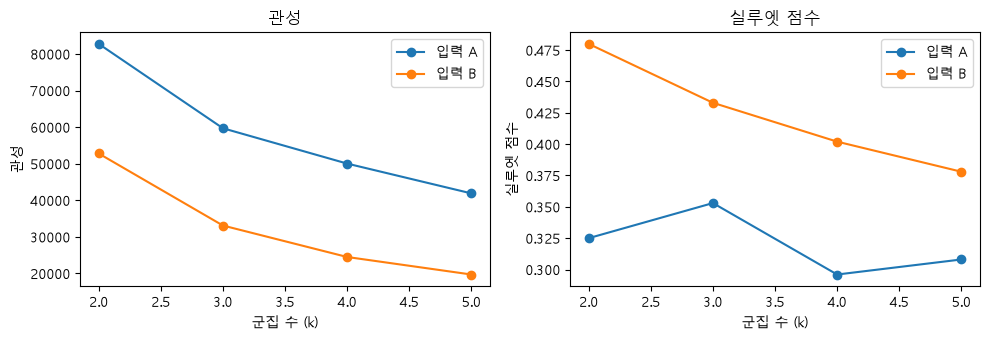

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
for df_s, label in [(score, "입력 A"), (score_alt, "입력 B")]:
    axes[0].plot(df_s["k"], df_s["관성"], marker="o", label=label)
    axes[1].plot(df_s["k"], df_s["실루엣"], marker="o", label=label)
axes[0].set_xlabel("군집 수 (k)")
axes[0].set_ylabel("관성")
axes[0].set_title("관성")
axes[1].set_xlabel("군집 수 (k)")
axes[1].set_ylabel("실루엣 점수")
axes[1].set_title("실루엣 점수")
axes[0].legend()
axes[1].legend()
plt.tight_layout()
plt.show()

### 결과
- 표본 크기 5,000·10,000·20,000건의 실루엣 0.351~0.357 (k=3 하나로 확인)
- `n_init` 1·10·30 비교(k=3): 10과 30은 관성·군집 크기가 같고, 1은 관성이 2 높고 군집 크기가 최대 434건 다름
- 입력 A: 실루엣 최댓값은 k=3 (0.353), k=4에서 0.296으로 내려간 뒤 k=5에서 0.308로 소폭 상승
- 입력 A: 관성은 k=2→3에서 23,066 감소, k=3→4에서 9,659, k=4→5에서 8,147 감소
- 입력 B: 실루엣 최댓값은 k=2 (0.480), k가 커질수록 계속 하락
- 관성은 두 입력 모두 k가 커질수록 계속 감소
- 선택한 군집 수: k=3 (입력 A 기준)

**표본 크기별 실루엣 (k=3)**

| 표본 크기 | 실루엣 |
|---|---|
| 5,000건 | 0.351 |
| 10,000건 | 0.353 |
| 20,000건 | 0.357 |

**`n_init`별 결과 (k=3)**

| n_init | 관성 | 군집 기록 수 (건) |
|---|---|---|
| 1 | 59,699 | 29,539 / 23,014 / 7,333 |
| 10 | 59,697 | 29,369 / 23,448 / 7,069 |
| 30 | 59,697 | 29,369 / 23,448 / 7,069 |

**k별 점수**

| k | 입력 A 관성 | 입력 A 실루엣 | 입력 B 관성 | 입력 B 실루엣 |
|---|---|---|---|---|
| 2 | 82,763 | 0.325 | 52,797 | 0.480 |
| 3 | 59,697 | 0.353 | 33,106 | 0.433 |
| 4 | 50,038 | 0.296 | 24,507 | 0.402 |
| 5 | 41,891 | 0.308 | 19,716 | 0.378 |

**k=3 선택 근거 (입력 A)**

| 근거 | 값 |
|---|---|
| 실루엣 점수 | k=2~5 중 최대 (0.353) |
| 관성 감소 폭 | k=2→3이 23,066으로 가장 큼 |
| 군집 수 범위 | 해석 가능한 수준을 고려한 k=2~5 이내 |

### 추정·한계
- 실루엣이 입력 A 최댓값 0.353으로 낮고 k=2(0.325)와 차이도 작아, 군집 경계가 뚜렷하지 않을 가능성이 있고 k=3은 확정된 군집 수가 아닌 해석용 설정임
- 입력이 다른 두 안의 점수 크기는 직접 비교하지 않음
- 표본 크기·`n_init` 확인은 k=3 하나, `random_state=42` 하나로만 했고 전체 기록 기준 실루엣은 계산하지 않음
- k=6 이상은 확인하지 않음

### 한 줄 정리
- 입력 A의 실루엣 점수가 k=3에서 0.353으로 가장 높고 관성 감소 폭도 k=2→3에서 가장 커 군집 수를 3개로 정함

## 4. 군집 결과 해석

**핵심:** 선택한 k=3으로 군집을 학습하고 군집 분포와 군집별 특징을 확인

### 작업 내용
- 입력 A(`X`)로 K-Means(k=3, `n_init=10`, `random_state=42`) 학습
- 군집 번호는 총 기록 중앙값이 짧은 순서로 1~3번 부여 (총 기록은 번호 정렬에만 사용, 군집 입력 아님)
- 런 비중·후반 런 하락 산점도로 군집 분포 확인
- 군집별 특징·총 기록 중앙값 비교

### 확인 포인트
- 군집별 기록 수
- 군집 간 경계의 겹침 정도
- 입력에 쓰지 않은 열(스테이션 비중, 록스존 비중, 총 기록)의 군집별 차이

군집
1    29369
2    23448
3     7069


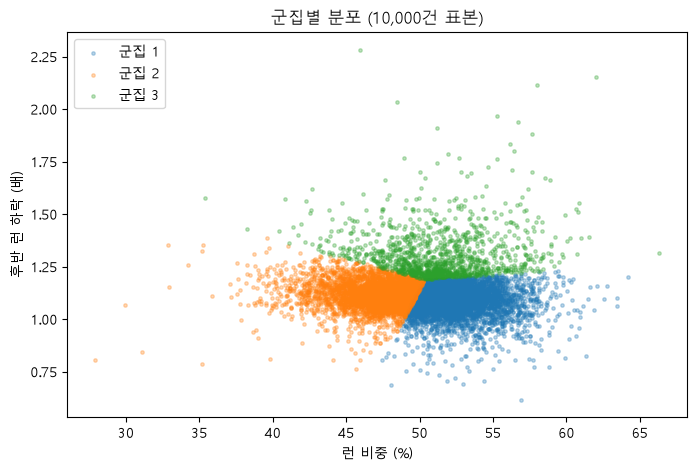

In [22]:
km = KMeans(n_clusters=3, n_init=10, random_state=42).fit(X)  # 전체 59,886건으로 학습
clean["군집_원본"] = km.labels_
order = clean.groupby("군집_원본")["total_sec"].median().sort_values().index  # 총 기록 중앙값이 짧은 순서
clean["군집"] = clean["군집_원본"].map({old: new for new, old in enumerate(order, start=1)})

print(clean["군집"].value_counts().sort_index().rename("기록 수(건)").to_string())

view = clean.join(features)  # 군집 열과 특징 열을 함께 보기 위한 표
plot_df = view.sample(10000, random_state=42)  # 앞의 실루엣 표본과 같은 크기
plt.figure(figsize=(8, 5))
for g, d in plot_df.groupby("군집"):
    plt.scatter(d["런 비중"] * 100, d["후반 런 하락"], s=6, alpha=0.3, label=f"군집 {g}")
plt.xlabel("런 비중 (%)")
plt.ylabel("후반 런 하락 (배)")
plt.title("군집별 분포 (10,000건 표본)")
plt.legend()
plt.show()

In [23]:
profile = view.groupby("군집").agg(
    **{
        "기록 수 (건)": ("군집", "size"),
        "런 비중": ("런 비중", "median"),
        "후반 런 하락": ("후반 런 하락", "median"),
        "스테이션 비중": ("스테이션 비중", "median"),
        "록스존 비중": ("록스존 비중", "median"),
        "총 기록 중앙값 (분)": ("total_sec", lambda s: s.median() / 60),
    }
).round(3)
print(profile.to_string())

    기록 수 (건)   런 비중  후반 런 하락  스테이션 비중  록스존 비중  총 기록 중앙값 (분)
군집                                                         
1      29369  0.521    1.092    0.405   0.070        83.967
2      23448  0.474    1.120    0.449   0.077        90.000
3       7069  0.511    1.271    0.408   0.078       103.217


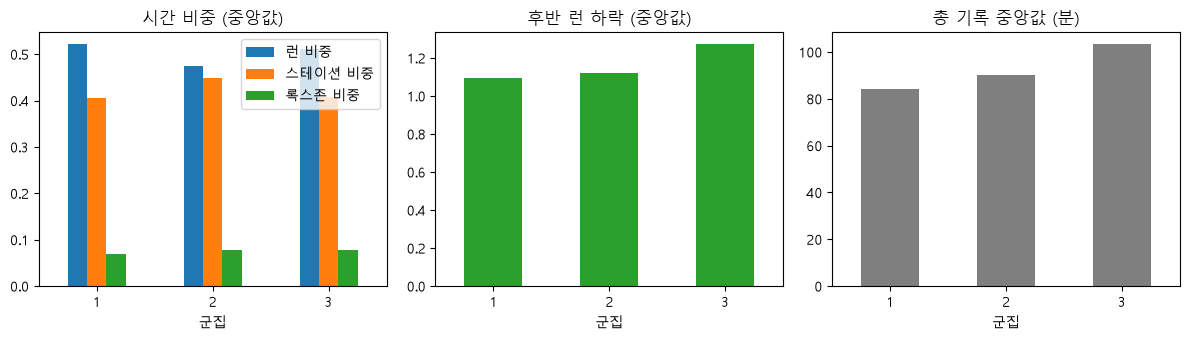

In [24]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.5))
profile[["런 비중", "스테이션 비중", "록스존 비중"]].plot.bar(ax=axes[0], rot=0)
axes[0].set_title("시간 비중 (중앙값)")
profile["후반 런 하락"].plot.bar(ax=axes[1], rot=0, color="tab:green")
axes[1].set_title("후반 런 하락 (중앙값)")
profile["총 기록 중앙값 (분)"].plot.bar(ax=axes[2], rot=0, color="tab:gray")
axes[2].set_title("총 기록 중앙값 (분)")
for ax in axes:
    ax.set_xlabel("군집")
plt.tight_layout()
plt.show()

### 결과
- 군집별 기록 수: 군집 1 29,369건, 군집 2 23,448건, 군집 3 7,069건
- 군집 번호는 총 기록 중앙값이 짧은 순서 (총 기록은 군집 입력에 쓰지 않음)
- 산점도에서 세 군집은 서로 이어진 한 덩어리 분포로 나뉘며, 떨어진 군집은 없음
- 군집 1: 런 비중 0.521로 가장 높고, 후반 런 하락 1.092로 가장 작음
- 군집 2: 런 비중 0.474로 가장 낮고, 스테이션 비중 0.449로 가장 높음
- 군집 3: 후반 런 하락 1.271로 가장 크고, 총 기록 중앙값 103.2분으로 가장 김
- 총 기록 중앙값은 군집 1 → 2 → 3 순으로 84.0분, 90.0분, 103.2분

**군집별 프로파일 (중앙값)**

| 군집 | 기록 수 (건) | 런 비중 | 후반 런 하락 | 스테이션 비중 | 록스존 비중 | 총 기록 중앙값 (분) |
|---|---|---|---|---|---|---|
| 1 | 29,369 | 0.521 | 1.092 | 0.405 | 0.070 | 83.967 |
| 2 | 23,448 | 0.474 | 1.120 | 0.449 | 0.077 | 90.000 |
| 3 | 7,069 | 0.511 | 1.271 | 0.408 | 0.078 | 103.217 |

- 런 비중·후반 런 하락은 군집 입력, 나머지 열은 입력에 쓰지 않은 확인용 값
- 후반 런 하락은 런 5~8구간 평균 ÷ 런 1~4구간 평균이며, 1보다 클수록 후반 런이 느림

### 추정·한계
- 군집 경계가 이어져 있어 뚜렷한 유형이 아니라 경향 수준의 구분임
- 군집 3의 후반 런 하락과 긴 총 기록이 함께 나타나는 원인(피로, 페이스 배분 등)은 확인 불가
- 군집별 값은 중앙값이라 군집 안의 폭은 보이지 않음
- 후반 런 하락의 극단 기록(표준화 후 최댓값 18.172)이 군집 중심에 준 영향은 이 노트북에서 검증하지 않음

### 한 줄 정리
- 런 비중과 후반 런 하락으로 나눈 3개 군집은 총 기록 중앙값이 84.0·90.0·103.2분으로 구분되며, 후반 런 하락이 1.271로 큰 군집 3이 가장 느림